In [1]:
import sys
import automata
import pytest

print("Python utilisé :", sys.executable)
print("automata-lib : OK")
print("pytest : OK")

Python utilisé : C:\Users\UGA-Valence\Documents\Projet_Automata\.venv\Scripts\python.exe
automata-lib : OK
pytest : OK


# Projet Automata
## Extension de la bibliothèque automata-lib

**Objectif :** développer des fonctionnalités supplémentaires
pour manipuler les automates finis, les langages et les grammaires.

In [2]:
from automata.fa.dfa import DFA

print("Classe DFA importée avec succès !")
print("Nom de la classe :", DFA.__name__)

Classe DFA importée avec succès !
Nom de la classe : DFA


In [3]:
from automata.fa.dfa import DFA

automate = DFA(
    states={"q0", "q1"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": "q1", "b": "q0"},
        "q1": {"a": "q0", "b": "q1"}
    },
    initial_state="q0",
    final_states={"q0"}
)

print("Automate créé avec succès !")
print("États :", automate.states)
print("Alphabet :", automate.input_symbols)
print("État initial :", automate.initial_state)
print("États finaux :", automate.final_states)

Automate créé avec succès !
États : frozenset({'q1', 'q0'})
Alphabet : frozenset({'b', 'a'})
État initial : q0
États finaux : frozenset({'q0'})


In [4]:
mots = ["", "a", "aa", "ab", "aba", "aab", "baba", "bbb"]

for mot in mots:
    if automate.accepts_input(mot):
        print(mot, "→ accepté")
    else:
        print(mot, "→ refusé")

 → accepté
a → refusé
aa → accepté
ab → refusé
aba → accepté
aab → accepté
baba → accepté
bbb → accepté


In [5]:
from automata.fa.fa import FA

print("Classe de base FA importée avec succès !")
print("Nom :", FA.__name__)

Classe de base FA importée avec succès !
Nom : FA


In [25]:
class AnalyseMixin:
    """Méthodes d'analyse des automates."""
    pass


class ConversionMixin:
    """Méthodes de conversion des automates."""
    pass


class GrammaireMixin:
    """Méthodes liées aux grammaires."""
    pass


class VisualisationMixin:
    """Méthodes de visualisation des automates."""
    pass


print("Les quatre Mixins sont créés !")

Les quatre Mixins sont créés !


In [7]:
class ExtendedFA(
    AnalyseMixin,
    ConversionMixin,
    GrammaireMixin,
    VisualisationMixin,
    FA
):
    """
    Classe de base étendue pour les automates finis.

    Elle regroupe les fonctionnalités d'analyse,
    de conversion, de grammaire et de visualisation.
    """

    pass


print("La classe ExtendedFA a été créée avec succès !")

La classe ExtendedFA a été créée avec succès !


In [8]:
print("ExtendedFA hérite de FA :", issubclass(ExtendedFA, FA))

print("ExtendedFA hérite de AnalyseMixin :",
      issubclass(ExtendedFA, AnalyseMixin))

print("ExtendedFA hérite de ConversionMixin :",
      issubclass(ExtendedFA, ConversionMixin))

print("ExtendedFA hérite de GrammaireMixin :",
      issubclass(ExtendedFA, GrammaireMixin))

print("ExtendedFA hérite de VisualisationMixin :",
      issubclass(ExtendedFA, VisualisationMixin))


ExtendedFA hérite de FA : True
ExtendedFA hérite de AnalyseMixin : True
ExtendedFA hérite de ConversionMixin : True
ExtendedFA hérite de GrammaireMixin : True
ExtendedFA hérite de VisualisationMixin : True


In [9]:
from automata.fa.dfa import DFA


class ExtendedDFA(ExtendedFA, DFA):
    """
    Automate fini déterministe étendu.

    Hérite des fonctionnalités de ExtendedFA
    et des fonctionnalités de DFA.
    """

    pass


print("ExtendedDFA créée avec succès !")

ExtendedDFA créée avec succès !


In [10]:
automate_etendu = ExtendedDFA(
    states={"q0", "q1"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": "q1", "b": "q0"},
        "q1": {"a": "q0", "b": "q1"}
    },
    initial_state="q0",
    final_states={"q0"}
)

print("Automate étendu créé avec succès !")

print("Nombre d'états :", len(automate_etendu.states))

print("Le mot 'aa' est accepté :",
      automate_etendu.accepts_input("aa"))

print("Le mot 'a' est accepté :",
      automate_etendu.accepts_input("a"))

Automate étendu créé avec succès !
Nombre d'états : 2
Le mot 'aa' est accepté : True
Le mot 'a' est accepté : False


In [11]:
from collections import deque

def parcours_bfs(automate, depart):
    visites = set()
    file = deque([depart])

    while file:
        etat = file.popleft()

        if etat not in visites:
            visites.add(etat)

            for symbole in automate.input_symbols:
                suivant = automate.transitions[etat].get(symbole)

                if suivant is not None and suivant not in visites:
                    file.append(suivant)

    return visites

In [12]:
resultat = parcours_bfs(automate_etendu, "q0")

print("États accessibles depuis q0 :", resultat)

États accessibles depuis q0 : {'q1', 'q0'}


In [26]:
from collections import deque


class AnalyseMixin:

    def accessibles(self, depart=None):
        """
        Calcule les états accessibles depuis un état donné.

        Si aucun état n'est fourni, le parcours commence
        depuis l'état initial.

        Complexité : O(|Q| + |E|).
        """
        if depart is None:
            depart = self.initial_state

        visites = set()
        file = deque([depart])

        while file:
            etat = file.popleft()

            if etat not in visites:
                visites.add(etat)

                for symbole in self.input_symbols:
                    suivant = self.transitions[etat].get(symbole)

                    if suivant is not None and suivant not in visites:
                        file.append(suivant)

        return visites


print("Méthode accessibles créée !")

Méthode accessibles créée !


In [14]:
class ExtendedFA(
    AnalyseMixin,
    ConversionMixin,
    GrammaireMixin,
    VisualisationMixin,
    FA
):
    pass


class ExtendedDFA(ExtendedFA, DFA):
    pass


print("Les classes étendues ont été mises à jour !")

Les classes étendues ont été mises à jour !


In [15]:
automate_etendu = ExtendedDFA(
    states={"q0", "q1"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": "q1", "b": "q0"},
        "q1": {"a": "q0", "b": "q1"}
    },
    initial_state="q0",
    final_states={"q0"}
)

print("États accessibles :", automate_etendu.accessibles())

États accessibles : {'q1', 'q0'}


In [46]:
from collections import deque


class AnalyseMixin:

    def accessibles(self, depart=None):
        if depart is None:
            depart = self.initial_state

        visites = set()
        file = deque([depart])

        while file:
            etat = file.popleft()

            if etat not in visites:
                visites.add(etat)

                for symbole in self.input_symbols:
                    suivant = self.transitions[etat].get(symbole)

                    if suivant is not None and suivant not in visites:
                        file.append(suivant)

        return visites

    def coaccessibles(self):
        """
        Calcule les états depuis lesquels un état final
        peut être atteint.

        Complexité : O(|Q| + |E|).
        """
        predecesseurs = {etat: set() for etat in self.states}

        # Construire les transitions inverses
        for etat in self.states:
            for suivant in self.transitions[etat].values():
                predecesseurs[suivant].add(etat)

        # Parcours en largeur à partir des états finaux
        visites = set(self.final_states)
        file = deque(self.final_states)

        while file:
            etat = file.popleft()

            for precedent in predecesseurs[etat]:
                if precedent not in visites:
                    visites.add(precedent)
                    file.append(precedent)

        return visites


print("Méthodes accessibles et coaccessibles créées !")

Méthodes accessibles et coaccessibles créées !


In [17]:
class ExtendedFA(
    AnalyseMixin,
    ConversionMixin,
    GrammaireMixin,
    VisualisationMixin,
    FA
):
    pass


class ExtendedDFA(ExtendedFA, DFA):
    pass

print("Classes mises à jour !")

Classes mises à jour !


In [18]:
automate_test = ExtendedDFA(
    states={"q0", "q1", "q2", "q3"},
    input_symbols={"a"},
    transitions={
        "q0": {"a": "q1"},
        "q1": {"a": "q2"},
        "q2": {"a": "q2"},
        "q3": {"a": "q3"}
    },
    initial_state="q0",
    final_states={"q2"}
)

In [19]:
print("États accessibles :", automate_test.accessibles())

print("États coaccessibles :", automate_test.coaccessibles())

États accessibles : {'q2', 'q1', 'q0'}
États coaccessibles : {'q2', 'q1', 'q0'}


In [20]:
def utiles(self):
    """
    Calcule les états utiles de l'automate.

    Un état utile est accessible depuis l'état initial
    et permet d'atteindre un état final.

    Complexité : O(|Q| + |E|).
    """
    return self.accessibles() & self.coaccessibles()

In [40]:
class ExtendedFA(
    AnalyseMixin,
    ConversionMixin,
    GrammaireMixin,
    VisualisationMixin,
    FA
):
    pass


class ExtendedDFA(ExtendedFA, DFA):
    pass

In [41]:
import sys
print("Python utilisé :", sys.executable)

import automata
import pytest

print("automata-lib : OK")
print("pytest : OK")

Python utilisé : C:\Users\UGA-Valence\Documents\Projet_Automata\.venv\Scripts\python.exe
automata-lib : OK
pytest : OK


In [42]:
print("AnalyseMixin :", hasattr(AnalyseMixin, "utiles"))
print("ExtendedFA :", hasattr(ExtendedFA, "utiles"))
print("ExtendedDFA :", hasattr(ExtendedDFA, "utiles"))

AnalyseMixin : True
ExtendedFA : True
ExtendedDFA : True


In [38]:
def utiles(self):
    """
    Calcule les états utiles de l'automate.

    Un état utile est à la fois accessible et coaccessible.

    Complexité : O(|Q| + |E|).
    """
    return self.accessibles() & self.coaccessibles()


AnalyseMixin.utiles = utiles

print("Méthode utiles ajoutée avec succès !")

Méthode utiles ajoutée avec succès !


In [39]:
print(hasattr(AnalyseMixin, "utiles"))

True


In [43]:
automate_test = ExtendedDFA(
    states={"q0", "q1", "q2", "q3"},
    input_symbols={"a"},
    transitions={
        "q0": {"a": "q1"},
        "q1": {"a": "q2"},
        "q2": {"a": "q2"},
        "q3": {"a": "q3"}
    },
    initial_state="q0",
    final_states={"q2"}
)

In [44]:
automate_test = ExtendedDFA(
    states={"q0", "q1", "q2", "q3"},
    input_symbols={"a"},
    transitions={
        "q0": {"a": "q1"},
        "q1": {"a": "q2"},
        "q2": {"a": "q2"},
        "q3": {"a": "q3"}
    },
    initial_state="q0",
    final_states={"q2"}
)

In [45]:
print("États accessibles :", automate_test.accessibles())
print("États coaccessibles :", automate_test.coaccessibles())
print("États utiles :", automate_test.utiles())

États accessibles : {'q2', 'q1', 'q0'}
États coaccessibles : {'q2', 'q1', 'q0'}
États utiles : {'q2', 'q1', 'q0'}


In [47]:
from collections import deque


class AnalyseMixin:
    """Méthodes d'analyse des automates finis."""

    def accessibles(self, depart=None):
        """Calcule les états accessibles depuis un état donné."""

        if depart is None:
            depart = self.initial_state

        visites = set()
        file = deque([depart])

        while file:
            etat = file.popleft()

            if etat not in visites:
                visites.add(etat)

                for symbole in self.input_symbols:
                    suivant = self.transitions[etat].get(symbole)

                    if suivant is not None and suivant not in visites:
                        file.append(suivant)

        return visites

    def coaccessibles(self):
        """Calcule les états pouvant atteindre un état final."""

        predecesseurs = {etat: set() for etat in self.states}

        for etat in self.states:
            for suivant in self.transitions[etat].values():
                predecesseurs[suivant].add(etat)

        visites = set(self.final_states)
        file = deque(self.final_states)

        while file:
            etat = file.popleft()

            for precedent in predecesseurs[etat]:
                if precedent not in visites:
                    visites.add(precedent)
                    file.append(precedent)

        return visites

    def utiles(self):
        """Calcule les états à la fois accessibles et coaccessibles."""

        return self.accessibles() & self.coaccessibles()

In [48]:
from automata_extensions.fa.mixins.analyse import AnalyseMixin

print("Importation de AnalyseMixin réussie !")

Importation de AnalyseMixin réussie !


In [49]:
print(hasattr(AnalyseMixin, "accessibles"))
print(hasattr(AnalyseMixin, "coaccessibles"))
print(hasattr(AnalyseMixin, "utiles"))

True
True
True


In [50]:
from automata_extensions.fa.base import ExtendedFA

print("Importation de ExtendedFA réussie !")

Importation de ExtendedFA réussie !


In [51]:
from automata_extensions.fa.dfa import ExtendedDFA

print("Importation de ExtendedDFA réussie !")

Importation de ExtendedDFA réussie !


In [52]:
from automata_extensions.fa.dfa import ExtendedDFA

automate = ExtendedDFA(
    states={"q0", "q1", "q2", "q3"},
    input_symbols={"a"},
    transitions={
        "q0": {"a": "q1"},
        "q1": {"a": "q2"},
        "q2": {"a": "q2"},
        "q3": {"a": "q3"}
    },
    initial_state="q0",
    final_states={"q2"}
)

print("Accessibles :", automate.accessibles())
print("Coaccessibles :", automate.coaccessibles())
print("Utiles :", automate.utiles())

Accessibles : {'q2', 'q1', 'q0'}
Coaccessibles : {'q2', 'q1', 'q0'}
Utiles : {'q2', 'q1', 'q0'}


In [1]:

from automata.fa.nfa import NFA

automate = NFA(
    states={"q0", "q1", "q2", "q3", "q4"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {
            "a": {"q1", "q2"}
        },
        "q1": {
            "b": {"q3"}
        },
        "q2": {
            "b": {"q4"}
        },
        "q3": {},
        "q4": {}
    },
    initial_state="q0",
    final_states={"q3", "q4"}
)

print("NFA créé avec succès !")


NFA créé avec succès !


In [2]:
print(automate.accepts_input("ab"))
print(automate.accepts_input("a"))

True
False


In [3]:
print("NFA créé avec succès !")

print("Le mot ab est accepté :", automate.accepts_input("ab"))
print("Le mot a est accepté :", automate.accepts_input("a"))

NFA créé avec succès !
Le mot ab est accepté : True
Le mot a est accepté : False


In [4]:
print(automate.states)

frozenset({'q3', 'q4', 'q2', 'q1', 'q0'})


In [5]:
print(automate.transitions)

frozendict.frozendict({'q0': frozendict.frozendict({'a': frozenset({'q2', 'q1'})}), 'q1': frozendict.frozendict({'b': frozenset({'q3'})}), 'q2': frozendict.frozendict({'b': frozenset({'q4'})}), 'q3': frozendict.frozendict({}), 'q4': frozendict.frozendict({})})


In [6]:
for etat in automate.states:
    print(etat)

q3
q4
q2
q1
q0


In [7]:
from automata_extensions.fa.mixins.analyse import AnalyseMixin

resultat = AnalyseMixin.accessibles_nfa(automate)

print("États accessibles :", resultat)

États accessibles : {'q3', 'q4', 'q2', 'q1', 'q0'}


In [8]:
import importlib
import automata_extensions.fa.mixins.analyse as analyse_module

importlib.reload(analyse_module)

resultat = analyse_module.AnalyseMixin.accessibles(automate)

print("États accessibles :", resultat)

États accessibles : {'q3', 'q4', 'q2', 'q1', 'q0'}


In [9]:
from automata_extensions.fa.dfa import ExtendedDFA

dfa = ExtendedDFA(
    states={"q0", "q1", "q2"},
    input_symbols={"a"},
    transitions={
        "q0": {"a": "q1"},
        "q1": {"a": "q2"},
        "q2": {"a": "q2"}
    },
    initial_state="q0",
    final_states={"q2"}
)

resultat_dfa = analyse_module.AnalyseMixin.accessibles(dfa)

print("États accessibles du DFA :", resultat_dfa)

États accessibles du DFA : {'q2', 'q1', 'q0'}


In [10]:
import importlib
import automata_extensions.fa.mixins.analyse as analyse_module

importlib.reload(analyse_module)

resultat = analyse_module.AnalyseMixin.coaccessibles(automate)

print("États coaccessibles :", resultat)

États coaccessibles : {'q3', 'q4', 'q2', 'q1', 'q0'}


In [11]:
resultat = (
    analyse_module.AnalyseMixin.accessibles(automate)
    & analyse_module.AnalyseMixin.coaccessibles(automate)
)

print("États utiles :", resultat)

États utiles : {'q3', 'q4', 'q2', 'q1', 'q0'}


In [13]:
from automata_extensions.fa.nfa import ExtendedNFA

nfa = ExtendedNFA(
    states={"q0", "q1", "q2", "q3", "q4"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": {"q1", "q2"}},
        "q1": {"b": {"q3"}},
        "q2": {"b": {"q4"}},
        "q3": {},
        "q4": {}
    },
    initial_state="q0",
    final_states={"q3", "q4"}
)

print("Accessibles :", nfa.accessibles())
print("Coaccessibles :", nfa.coaccessibles())
print("Utiles :", nfa.utiles())

Accessibles : {'q3', 'q4', 'q2', 'q1', 'q0'}


KeyError: frozenset({'q4'})

In [14]:
print(nfa.transitions)

frozendict.frozendict({'q0': frozendict.frozendict({'a': frozenset({'q2', 'q1'})}), 'q1': frozendict.frozendict({'b': frozenset({'q3'})}), 'q2': frozendict.frozendict({'b': frozenset({'q4'})}), 'q3': frozendict.frozendict({}), 'q4': frozendict.frozendict({})})


In [15]:
import importlib
import automata_extensions.fa.mixins.analyse as analyse_module

importlib.reload(analyse_module)

print("Accessibles :", nfa.accessibles())
print("Coaccessibles :", nfa.coaccessibles())
print("Utiles :", nfa.utiles())

Accessibles : {'q3', 'q4', 'q2', 'q1', 'q0'}


KeyError: frozenset({'q4'})

In [16]:
import importlib

import automata_extensions.fa.mixins.analyse as analyse_module
import automata_extensions.fa.base as base_module
import automata_extensions.fa.nfa as nfa_module

# Recharger les modules dans le bon ordre
importlib.reload(analyse_module)
importlib.reload(base_module)
importlib.reload(nfa_module)

# Importer la nouvelle classe
from automata_extensions.fa.nfa import ExtendedNFA

# Recréer le NFA
nfa = ExtendedNFA(
    states={"q0", "q1", "q2", "q3", "q4"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": {"q1", "q2"}},
        "q1": {"b": {"q3"}},
        "q2": {"b": {"q4"}},
        "q3": {},
        "q4": {}
    },
    initial_state="q0",
    final_states={"q3", "q4"}
)

# Tester les trois méthodes
print("Accessibles :", nfa.accessibles())
print("Coaccessibles :", nfa.coaccessibles())
print("Utiles :", nfa.utiles())

Accessibles : {'q3', 'q4', 'q2', 'q1', 'q0'}
Coaccessibles : {'q3', 'q4', 'q2', 'q1', 'q0'}
Utiles : {'q3', 'q4', 'q2', 'q1', 'q0'}


In [1]:
import inspect
from automata.fa.nfa import NFA

print(inspect.signature(NFA))

(*, states: 'AbstractSet[NFAStateT]', input_symbols: 'AbstractSet[str]', transitions: 'NFATransitionsT', initial_state: 'NFAStateT', final_states: 'AbstractSet[NFAStateT]') -> 'None'


In [2]:
from automata.fa.nfa import NFA

print(NFA.__doc__)


The `NFA` class is a subclass of `FA` and represents a nondeterministic finite
automaton.

Every NFA has the same five DFA properties: `state`, `input_symbols`,
`transitions`, `initial_state`, and `final_states`. However, the structure of
the `transitions` object has been modified slightly to accommodate the fact that
a single state can have more than one transition for the same symbol. Therefore,
instead of mapping a symbol to *one* end state in each sub-dict, each symbol is
mapped to a *set* of end states.

Every NFA can be rendered natively inside of a Jupyter notebook (automatically
calling `show_diagram` without any arguments) if installed with the `visual`
optional dependency.

Parameters
----------
states : AbstractSet[NFAStateT]
    Set of the NFA's valid states.
input_symbols : AbstractSet[str]
    Set of the NFA's valid input symbols, each of which is a singleton
    string.
transitions : Mapping[NFAStateT, Mapping[str, AbstractSet[NFAStateT]]]
    Dict consisting of the tra

In [3]:
from automata_extensions.fa.nfa import ExtendedNFA

automate = ExtendedNFA(
    states={'q0', 'q1', 'q2'},
    input_symbols={'a', 'b'},
    transitions={
        'q0': {'a': {'q1'}},
        'q1': {'b': {'q2'}},
        'q2': {}
    },
    initial_state='q0',
    final_states={'q2'}
)

automate_inverse = automate.reverse()

print("États :", automate_inverse.states)
print("État initial :", automate_inverse.initial_state)
print("États finaux :", automate_inverse.final_states)
print("Transitions :", automate_inverse.transitions)

États : frozenset({'q1', 'q_initial_inverse', 'q2', 'q0'})
État initial : q_initial_inverse
États finaux : frozenset({'q0'})
Transitions : frozendict.frozendict({'q1': frozendict.frozendict({'a': frozenset({'q0'})}), 'q2': frozendict.frozendict({'b': frozenset({'q1'})}), 'q0': frozendict.frozendict({}), 'q_initial_inverse': frozendict.frozendict({'': frozenset({'q2'})})})


In [4]:
print("Mot ba :", automate_inverse.accepts_input("ba"))
print("Mot ab :", automate_inverse.accepts_input("ab"))

Mot ba : True
Mot ab : False


In [5]:
from automata_extensions.fa.dfa import ExtendedDFA

automate_dfa = ExtendedDFA(
    states={'q0', 'q1', 'q2'},
    input_symbols={'a', 'b'},
    transitions={
        'q0': {'a': 'q1', 'b': 'q0'},
        'q1': {'a': 'q1', 'b': 'q2'},
        'q2': {'a': 'q2', 'b': 'q2'}
    },
    initial_state='q0',
    final_states={'q2'}
)

inverse_dfa = automate_dfa.reverse()

print("Type :", type(inverse_dfa))
print("État initial :", inverse_dfa.initial_state)
print("États finaux :", inverse_dfa.final_states)
print("Transitions :", inverse_dfa.transitions)

print("Mot ba :", inverse_dfa.accepts_input("ba"))

Type : <class 'automata.fa.nfa.NFA'>
État initial : q_initial_inverse
États finaux : frozenset({'q0'})
Transitions : frozendict.frozendict({'q1': frozendict.frozendict({'a': frozenset({'q1', 'q0'})}), 'q2': frozendict.frozendict({'b': frozenset({'q1', 'q2'}), 'a': frozenset({'q2'})}), 'q0': frozendict.frozendict({'b': frozenset({'q0'})}), 'q_initial_inverse': frozendict.frozendict({'': frozenset({'q2'})})})
Mot ba : True


In [3]:
from automata_extensions.fa.nfa import ExtendedNFA

automate = ExtendedNFA(
    states={'q0', 'q1', 'q2'},
    input_symbols={'a', 'b'},
    transitions={
        'q0': {'a': {'q1'}},
        'q1': {'b': {'q2'}},
        'q2': {}
    },
    initial_state='q0',
    final_states={'q2'}
)

In [4]:
inverse = automate.reverse()

print(type(inverse))
print("Accessibles :", inverse.accessibles())
print("Coaccessibles :", inverse.coaccessibles())
print("Utiles :", inverse.utiles())

<class 'automata_extensions.fa.nfa.ExtendedNFA'>
Accessibles : {'q_initial_inverse', 'q2', 'q1', 'q0'}
Coaccessibles : {'q1', 'q2', 'q_initial_inverse', 'q0'}
Utiles : {'q1', 'q2', 'q0', 'q_initial_inverse'}


In [5]:
from automata.fa.dfa import DFA
import inspect

print(inspect.signature(DFA))

(*, states: 'AbstractSet[DFAStateT]', input_symbols: 'AbstractSet[str]', transitions: 'DFATransitionsT', initial_state: 'DFAStateT', final_states: 'AbstractSet[DFAStateT]', allow_partial: 'bool' = False) -> 'None'


In [6]:
from automata_extensions.fa.dfa import ExtendedDFA

automate = ExtendedDFA(
    states={"q0", "q1"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": "q1"},
        "q1": {"b": "q0"}
    },
    initial_state="q0",
    final_states={"q1"},
    allow_partial=True
)

print("Automate créé :", automate.states)
print("Transitions :", automate.transitions)

Automate créé : frozenset({'q1', 'q0'})
Transitions : frozendict.frozendict({'q0': frozendict.frozendict({'a': 'q1'}), 'q1': frozendict.frozendict({'b': 'q0'})})


In [7]:
from automata_extensions.fa.dfa import ExtendedDFA

automate = ExtendedDFA(
    states={"q0", "q1"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": "q1"},
        "q1": {"b": "q0"}
    },
    initial_state="q0",
    final_states={"q1"},
    allow_partial=True
)

automate.complete()

AttributeError: 'ExtendedDFA' object has no attribute 'complete'

In [8]:
import importlib
import automata_extensions.fa.mixins.conversions as conversions

importlib.reload(conversions)

<module 'automata_extensions.fa.mixins.conversions' from 'C:\\Users\\UGA-Valence\\Documents\\Projet_Automata\\automata_extensions\\fa\\mixins\\conversions.py'>

In [9]:
import automata_extensions.fa.base as base
import automata_extensions.fa.dfa as dfa

importlib.reload(base)
importlib.reload(dfa)

print(hasattr(dfa.ExtendedDFA, "complete"))

True


In [10]:
automate = dfa.ExtendedDFA(
    states={"q0", "q1"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": "q1"},
        "q1": {"b": "q0"}
    },
    initial_state="q0",
    final_states={"q1"},
    allow_partial=True
)

automate.complete()

[('q1', 'a'), ('q0', 'b')]


In [11]:
import importlib
import automata_extensions.fa.mixins.conversions as conversions
import automata_extensions.fa.base as base
import automata_extensions.fa.dfa as dfa

importlib.reload(conversions)
importlib.reload(base)
importlib.reload(dfa)

<module 'automata_extensions.fa.dfa' from 'C:\\Users\\UGA-Valence\\Documents\\Projet_Automata\\automata_extensions\\fa\\dfa.py'>

In [12]:
automate = dfa.ExtendedDFA(
    states={"q0", "q1"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": "q1"},
        "q1": {"b": "q0"}
    },
    initial_state="q0",
    final_states={"q1"},
    allow_partial=True
)

automate_complet = automate.complete()

print("États :", automate_complet.states)
print("Transitions :", automate_complet.transitions)
print("État initial :", automate_complet.initial_state)
print("États finaux :", automate_complet.final_states)

États : frozenset({'q1', 'q_puits', 'q0'})
Transitions : frozendict.frozendict({'q0': frozendict.frozendict({'a': 'q1', 'b': 'q_puits'}), 'q1': frozendict.frozendict({'b': 'q0', 'a': 'q_puits'}), 'q_puits': frozendict.frozendict({'b': 'q_puits', 'a': 'q_puits'})})
État initial : q0
États finaux : frozenset({'q1'})


In [16]:
import importlib
import automata_extensions.fa.mixins.conversions as conversions
import automata_extensions.fa.base as base
import automata_extensions.fa.dfa as dfa
import automata_extensions.fa.nfa as nfa

importlib.reload(conversions)
importlib.reload(base)
importlib.reload(dfa)
importlib.reload(nfa)

<module 'automata_extensions.fa.nfa' from 'C:\\Users\\UGA-Valence\\Documents\\Projet_Automata\\automata_extensions\\fa\\nfa.py'>

In [17]:
automate_nfa = nfa.ExtendedNFA(
    states={"q0", "q1"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": {"q1"}},
        "q1": {"b": {"q0"}}
    },
    initial_state="q0",
    final_states={"q1"}
)

automate_nfa.complete()

TypeError: La méthode complete() est réservée aux DFA.

In [18]:
automate_complet_test = dfa.ExtendedDFA(
    states={"q0", "q1"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": "q1", "b": "q0"},
        "q1": {"a": "q1", "b": "q0"}
    },
    initial_state="q0",
    final_states={"q1"}
)

resultat = automate_complet_test.complete()

print("Même automate :", resultat is automate_complet_test)
print("États :", resultat.states)

Même automate : True
États : frozenset({'q1', 'q0'})


In [19]:
automate_conflit = dfa.ExtendedDFA(
    states={"q0", "q1", "q_puits"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": "q1"},
        "q1": {"b": "q0"},
        "q_puits": {"a": "q_puits", "b": "q_puits"}
    },
    initial_state="q0",
    final_states={"q1"},
    allow_partial=True
)

resultat = automate_conflit.complete()

print("États :", resultat.states)
print("Transitions de q0 :", resultat.transitions["q0"])

États : frozenset({'q1', 'q_puits_', 'q_puits', 'q0'})
Transitions de q0 : frozendict.frozendict({'a': 'q1', 'b': 'q_puits_'})


In [20]:
import importlib

import automata_extensions.fa.mixins.conversions as conversions
import automata_extensions.fa.base as base
import automata_extensions.fa.dfa as dfa

importlib.reload(conversions)
importlib.reload(base)
importlib.reload(dfa)

<module 'automata_extensions.fa.dfa' from 'C:\\Users\\UGA-Valence\\Documents\\Projet_Automata\\automata_extensions\\fa\\dfa.py'>

In [21]:
automate = dfa.ExtendedDFA(
    states={"q0", "q1"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": "q1", "b": "q0"},
        "q1": {"a": "q1", "b": "q0"}
    },
    initial_state="q0",
    final_states={"q1"}
)

In [22]:
automate_complement = automate.complement()

print("États :", automate_complement.states)
print("États initiaux :", automate_complement.initial_state)
print("États finaux :", automate_complement.final_states)
print("Transitions :", automate_complement.transitions)

États : frozenset({'q1', 'q0'})
États initiaux : q0
États finaux : frozenset({'q0'})
Transitions : frozendict.frozendict({'q0': frozendict.frozendict({'a': 'q1', 'b': 'q0'}), 'q1': frozendict.frozendict({'a': 'q1', 'b': 'q0'})})


In [23]:
mots = ["", "a", "b", "aa", "ab", "ba", "bb"]

for mot in mots:
    print(
        repr(mot),
        "Original :", automate.accepts_input(mot),
        "| Complément :", automate_complement.accepts_input(mot)
    )

'' Original : False | Complément : True
'a' Original : True | Complément : False
'b' Original : False | Complément : True
'aa' Original : True | Complément : False
'ab' Original : False | Complément : True
'ba' Original : True | Complément : False
'bb' Original : False | Complément : True


In [24]:
import importlib

import automata_extensions.fa.mixins.conversions as conversions
import automata_extensions.fa.base as base
import automata_extensions.fa.dfa as dfa

importlib.reload(conversions)
importlib.reload(base)
importlib.reload(dfa)

<module 'automata_extensions.fa.dfa' from 'C:\\Users\\UGA-Valence\\Documents\\Projet_Automata\\automata_extensions\\fa\\dfa.py'>

In [25]:
automate_trim = dfa.ExtendedDFA(
    states={"q0", "q1", "q2", "q3"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": "q1", "b": "q2"},
        "q1": {"a": "q1"},
        "q2": {"b": "q2"},
        "q3": {"a": "q3", "b": "q3"}
    },
    initial_state="q0",
    final_states={"q1"},
    allow_partial=True
)

In [26]:
print("États accessibles :", automate_trim.accessibles())
print("États coaccessibles :", automate_trim.coaccessibles())
print("États utiles :", automate_trim.utiles())

États accessibles : {'q1', 'q2', 'q0'}
États coaccessibles : {'q1', 'q0'}
États utiles : {'q1', 'q0'}


In [28]:
import importlib

import automata_extensions.fa.mixins.conversions as conversions
import automata_extensions.fa.base as base
import automata_extensions.fa.dfa as dfa

importlib.reload(conversions)
importlib.reload(base)
importlib.reload(dfa)

<module 'automata_extensions.fa.dfa' from 'C:\\Users\\UGA-Valence\\Documents\\Projet_Automata\\automata_extensions\\fa\\dfa.py'>

In [30]:
automate_trim = dfa.ExtendedDFA(
    states={"q0", "q1", "q2", "q3"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": "q1", "b": "q2"},
        "q1": {"a": "q1"},
        "q2": {"b": "q2"},
        "q3": {"a": "q3", "b": "q3"}
    },
    initial_state="q0",
    final_states={"q1"},
    allow_partial=True
)

In [31]:
automate_reduit = automate_trim.trim()

print("États après trim :", automate_reduit.states)
print("États finaux :", automate_reduit.final_states)
print("Transitions :", automate_reduit.transitions)

États après trim : frozenset({'q1', 'q0'})
États finaux : frozenset({'q1'})
Transitions : frozendict.frozendict({'q1': frozendict.frozendict({'a': 'q1'}), 'q0': frozendict.frozendict({'a': 'q1'})})


In [32]:
from automata_extensions.fa.nfa import ExtendedNFA

automate_nfa = ExtendedNFA(
    states={"q0", "q1", "q2"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": {"q1", "q2"}},
        "q1": {"b": {"q1"}},
        "q2": {"b": {"q2"}}
    },
    initial_state="q0",
    final_states={"q1"}
)

In [33]:
nfa_reduit = automate_nfa.trim()

print("États après trim :", nfa_reduit.states)
print("États finaux :", nfa_reduit.final_states)
print("Transitions :", nfa_reduit.transitions)

AttributeError: 'ExtendedNFA' object has no attribute 'trim'

In [34]:
import importlib

import automata_extensions.fa.mixins.conversions as conversions
import automata_extensions.fa.base as base
import automata_extensions.fa.nfa as nfa

importlib.reload(conversions)
importlib.reload(base)
importlib.reload(nfa)

<module 'automata_extensions.fa.nfa' from 'C:\\Users\\UGA-Valence\\Documents\\Projet_Automata\\automata_extensions\\fa\\nfa.py'>

In [35]:
automate_nfa = nfa.ExtendedNFA(
    states={"q0", "q1", "q2"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": {"q1", "q2"}},
        "q1": {"b": {"q1"}},
        "q2": {"b": {"q2"}}
    },
    initial_state="q0",
    final_states={"q1"}
)

In [36]:
nfa_reduit = automate_nfa.trim()

print("États après trim :", nfa_reduit.states)
print("États finaux :", nfa_reduit.final_states)
print("Transitions :", nfa_reduit.transitions)

États après trim : frozenset({'q1', 'q0'})
États finaux : frozenset({'q1'})
Transitions : frozendict.frozendict({'q1': frozendict.frozendict({'b': frozenset({'q1'})}), 'q0': frozendict.frozendict({'a': frozenset({'q1'})})})


In [37]:
import importlib

import automata_extensions.fa.mixins.conversions as conversions
import automata_extensions.fa.base as base
import automata_extensions.fa.nfa as nfa
import automata_extensions.fa.dfa as dfa

importlib.reload(conversions)
importlib.reload(base)
importlib.reload(nfa)
importlib.reload(dfa)

<module 'automata_extensions.fa.dfa' from 'C:\\Users\\UGA-Valence\\Documents\\Projet_Automata\\automata_extensions\\fa\\dfa.py'>

In [38]:
print(hasattr(nfa.ExtendedNFA, "to_dfa"))

True


In [39]:
automate = nfa.ExtendedNFA(
    states={"q0", "q1", "q2"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": {"q1", "q2"}},
        "q1": {"b": {"q1"}},
        "q2": {"b": {"q2"}}
    },
    initial_state="q0",
    final_states={"q2"}
)

automate_dfa = automate.to_dfa()

print("États du DFA :", automate_dfa.states)
print("État initial :", automate_dfa.initial_state)
print("États finaux :", automate_dfa.final_states)
print("Transitions :", automate_dfa.transitions)

États du DFA : frozenset({frozenset({'q1', 'q2'}), frozenset({'q0'})})
État initial : frozenset({'q0'})
États finaux : frozenset({frozenset({'q1', 'q2'})})
Transitions : frozendict.frozendict({frozenset({'q0'}): frozendict.frozendict({'a': frozenset({'q1', 'q2'})}), frozenset({'q1', 'q2'}): frozendict.frozendict({'b': frozenset({'q1', 'q2'})})})


In [40]:
import importlib

import automata_extensions.fa.mixins.analyse as analyse
import automata_extensions.fa.base as base
import automata_extensions.fa.nfa as nfa

importlib.reload(analyse)
importlib.reload(base)
importlib.reload(nfa)

<module 'automata_extensions.fa.nfa' from 'C:\\Users\\UGA-Valence\\Documents\\Projet_Automata\\automata_extensions\\fa\\nfa.py'>

In [41]:
automate_epsilon = nfa.ExtendedNFA(
    states={"q0", "q1", "q2"},
    input_symbols={"a"},
    transitions={
        "q0": {"": {"q1"}},
        "q1": {"": {"q2"}},
        "q2": {"a": {"q2"}}
    },
    initial_state="q0",
    final_states={"q2"}
)

In [42]:
print(automate_epsilon.epsilon_closure({"q0"}))

{'q1', 'q2', 'q0'}


In [43]:
import importlib

import automata_extensions.fa.mixins.analyse as analyse
import automata_extensions.fa.mixins.conversions as conversions
import automata_extensions.fa.base as base
import automata_extensions.fa.nfa as nfa
import automata_extensions.fa.dfa as dfa

importlib.reload(analyse)
importlib.reload(conversions)
importlib.reload(base)
importlib.reload(nfa)
importlib.reload(dfa)

<module 'automata_extensions.fa.dfa' from 'C:\\Users\\UGA-Valence\\Documents\\Projet_Automata\\automata_extensions\\fa\\dfa.py'>

In [44]:
automate_epsilon = nfa.ExtendedNFA(
    states={"q0", "q1", "q2"},
    input_symbols={"a"},
    transitions={
        "q0": {"": {"q1"}},
        "q1": {"": {"q2"}},
        "q2": {"a": {"q2"}}
    },
    initial_state="q0",
    final_states={"q2"}
)

In [45]:
dfa_epsilon = automate_epsilon.to_dfa()

print("États du DFA :", dfa_epsilon.states)
print("État initial :", dfa_epsilon.initial_state)
print("États finaux :", dfa_epsilon.final_states)
print("Transitions :", dfa_epsilon.transitions)

États du DFA : frozenset({frozenset({'q2'}), frozenset({'q1', 'q2', 'q0'})})
État initial : frozenset({'q1', 'q2', 'q0'})
États finaux : frozenset({frozenset({'q2'}), frozenset({'q1', 'q2', 'q0'})})
Transitions : frozendict.frozendict({frozenset({'q1', 'q2', 'q0'}): frozendict.frozendict({'a': frozenset({'q2'})}), frozenset({'q2'}): frozendict.frozendict({'a': frozenset({'q2'})})})


In [46]:
from automata.fa.gnfa import GNFA
import inspect

print(inspect.signature(GNFA))

(*, states: 'AbstractSet[GNFAStateT]', input_symbols: 'AbstractSet[str]', transitions: 'GNFATransitionsT', initial_state: 'GNFAStateT', final_state: 'GNFAStateT') -> 'None'


In [47]:
from automata_extensions.fa.gnfa import ExtendedGNFA

print(ExtendedGNFA)

<class 'automata_extensions.fa.gnfa.ExtendedGNFA'>


In [48]:
from automata.fa.gnfa import GNFA
import inspect

print(inspect.getsource(GNFA))

class GNFA(fa.FA):
    """
    The `GNFA` class is a subclass of `FA` and represents a generalized
    nondeterministic finite automaton.

    Its main usage is for conversion of DFAs and NFAs to regular expressions using
    Kleene's algorithm (see https://en.wikipedia.org/wiki/Kleene%27s_algorithm).
    To convert an NFA to a regular expression, use `GNFA.from_nfa(nfa).to_regex()`.
    To convert a DFA to a regular expression, use `GNFA.from_dfa(dfa).to_regex()`.

    Note that because of this conversion purpose, the `GNFA` doesn't support any
    binary operators or reading input (for example, `read_input_stepwise`).
    Every GNFA can be rendered natively inside of a Jupyter notebook
    (automatically calling `show_diagram` without any arguments) if installed
    with the `visual` optional dependency. Note that `input_str` cannot be set
    as an argument to `show_diagram`, as the `GNFA` does not read input.

    Except for `initial_state` and `final_state`, one transition goes fr

In [49]:
from automata_extensions.fa.dfa import ExtendedDFA

automate = ExtendedDFA(
    states={"q0", "q1"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": "q1", "b": "q0"},
        "q1": {"a": "q1", "b": "q0"}
    },
    initial_state="q0",
    final_states={"q1"}
)

automate.display()

AttributeError: 'ExtendedDFA' object has no attribute 'display'

In [50]:
import importlib
import automata_extensions.fa.base
import automata_extensions.fa.dfa

importlib.reload(automata_extensions.fa.base)
importlib.reload(automata_extensions.fa.dfa)

from automata_extensions.fa.dfa import ExtendedDFA

In [51]:
automate.display()

AttributeError: 'ExtendedDFA' object has no attribute 'display'

In [52]:
import importlib

import automata_extensions.fa.mixins.visualisation as visualisation
import automata_extensions.fa.base as base
import automata_extensions.fa.dfa as dfa

importlib.reload(visualisation)
importlib.reload(base)
importlib.reload(dfa)

from automata_extensions.fa.dfa import ExtendedDFA

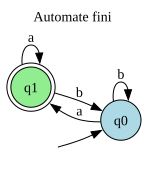

In [53]:
automate = ExtendedDFA(
    states={"q0", "q1"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {"a": "q1", "b": "q0"},
        "q1": {"a": "q1", "b": "q0"}
    },
    initial_state="q0",
    final_states={"q1"}
)

automate.display()